# Week 2 — the claims domain and EDA

You will make the plots from today's slides on **your own cohort**, and write
one short sentence under each one. That sentence is the deliverable, not the
plot.

| TODO | You make | Slide |
|---|---|---|
| 1 | Rows vs. members in each file | *Three files, joined on member_id* |
| 2 | Plan-paid on a linear and a log axis | *Look at the shape of the money first* |
| 3 | Share of spend held by the top X% | *How much spend sits with the top few?* |
| 4–5 | Prevalence, then prevalence as the line moves | *Find your prevalence before accuracy* |
| 6 | High-cost rate by group, with intervals | *Compare groups with intervals, not bars* |
| 7 | "Known on day one?" for every column | *On the day I need this prediction…* |
| 8 | Four data checks | *Run four checks before you trust a figure* |

**Run:**

```bash
pip install -r requirements-dev.txt
jupyter notebook notebooks/week-02-eda.ipynb
```

**How each TODO works**

- **Hints:** which columns and which pandas call. Not the answer.
- **What you should see:** a *range*. Your seed gives you your own cohort, so
  your numbers won't match your neighbour's. Outside the range means something
  is wrong.
- **Your conclusion:** fill in the `______`. One sentence is enough.

Each TODO cell stands on its own, so you can work them in any order.

---

## 0. Setup

In [1]:
# Given — nothing to do here.
import os
import random
import sys
import uuid
from pathlib import Path

# Notebooks have no __file__, and every script in this repo assumes the repo
# root is the working directory. Walk up until we find config.py.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config.py").exists()), None)
if ROOT is None:
    raise RuntimeError(
        f"No config.py in {Path.cwd()} or any directory above it. Run this "
        "notebook from inside your clone of the repo."
    )
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from config import HIGH_COST_THRESHOLD_USD, STUDENT_SEED


def cohort_is_current() -> bool:
    """Is the data in data/ the cohort THIS seed produces?"""
    if not (Path("data/members.csv").exists()
            and Path("data/member_summary.csv").exists()):
        return False
    random.seed(STUDENT_SEED)
    expected_first_id = str(uuid.UUID(int=random.getrandbits(128), version=4))
    on_disk = pd.read_csv("data/members.csv", nrows=1).iloc[0]["member_id"]
    return on_disk == expected_first_id


# The data is gitignored, so make it when it is missing or from another seed.
if not cohort_is_current():
    print(f"Generating the cohort for STUDENT_SEED={STUDENT_SEED} ...")
    from generate_claims_data import generate

    generate()
    print()

# procedure_code holds CPT codes. Read them as text, or "99213" becomes 99213.0.
members = pd.read_csv("data/members.csv")
claims = pd.read_csv("data/claims.csv", dtype={"procedure_code": "string"})
summary = pd.read_csv("data/member_summary.csv")

assert cohort_is_current(), "data/ does not match STUDENT_SEED — regenerate it"
print(f"STUDENT_SEED        {STUDENT_SEED}")
print(f"dollar threshold    ${HIGH_COST_THRESHOLD_USD:,}")
print(f"members / claims    {len(members):,} / {len(claims):,}")

STUDENT_SEED        6
dollar threshold    $25,000
members / claims    2,000 / 21,665


If the seed printed above is not the one you were assigned, stop and fix it
first — see *Your own cohort* in the README.

In [2]:
# Given — nothing to do here. Use these helpers; don't rewrite them.
BLUE, ORANGE = "#2a78d6", "#eb6834"      # orange = high-cost, everywhere
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e2e1dd"

sns.set_theme(context="notebook", style="whitegrid")
plt.rcParams.update({
    "axes.edgecolor": GRID,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": GRID,
    "legend.frameon": False,
    "figure.dpi": 110,
})


def dollars(cents):
    """Cents -> dollars. Every money column in this dataset is in cents."""
    return cents / 100


def usd(x, _pos=None):
    """Axis-tick formatter: ax.xaxis.set_major_formatter(plt.FuncFormatter(usd))."""
    for cut, suffix in ((1e6, "M"), (1e3, "k")):
        if abs(x) >= cut:
            scaled = x / cut
            digits = 0 if scaled == int(scaled) else 1
            return f"${scaled:,.{digits}f}{suffix}"
    return f"${x:,.0f}"


def threshold_line(ax, x=None):
    """Draw the $ dollar threshold as a dashed, labelled vertical line."""
    x = HIGH_COST_THRESHOLD_USD if x is None else x
    ax.axvline(x, color=MUTED, linewidth=1.2, linestyle="--", zorder=1)
    ax.annotate(f"dollar threshold ${x:,}", xy=(x, 1),
                xycoords=("data", "axes fraction"), xytext=(4, -12),
                textcoords="offset points", color=MUTED, fontsize=9)


def wilson_interval(k, n, z=1.96):
    """
    95% interval for a rate k/n. Returns (lo, hi).

    Works on single numbers or on whole columns at once:
        table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
    """
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return np.clip(centre - half, 0, 1), np.clip(centre + half, 0, 1)


def plot_rates(table, ax, title):
    """
    One row per group: a dot for the rate and a line for its 95% interval.
    The dashed line is the rate for the whole cohort.

    `table` needs columns rate, lo and hi, with the group names as its index.
    """
    y = np.arange(len(table))[::-1]
    ax.hlines(y, table["lo"], table["hi"], color=BLUE, linewidth=2)
    ax.plot(table["rate"], y, "o", color=BLUE)
    ax.axvline(summary["is_high_cost"].mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.set_yticks(y, table.index)
    ax.set(title=title, xlabel="high-cost rate (95% interval)", xlim=(0, 0.13))
    ax.set_xticks([0, 0.04, 0.08, 0.12])
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))


# Plan-paid per member, in dollars. Most TODOs start from this.
paid = dollars(summary["total_plan_paid_cents"])

DEMOGRAPHIC_COLUMNS = ["age_bucket", "sex", "region"]
AGE_ORDER = ["18-29", "30-39", "40-49", "50-59", "60-64"]

print("Helpers are ready.")

Helpers are ready.


---

## 1. Why we are doing this

Three teams could act on a high-cost prediction: **care management** (who do we
call?), **reserves** (how much money do we set aside?) and **pricing** (what do
we charge next year?). You'll pick yours in Week 5.

Whichever you pick, two things are already true:

1. **High-cost members are rare.** Most members cost very little.
2. **The prediction has to be made before the spending happens.** On January 1,
   not December 31.

Every TODO below checks one of those, or checks that the data is safe to use.

---

## 2. Three files, joined on `member_id`

First, find out what one row means in each file.

In [3]:
# ---------------------------------------------------------------------------
# TODO 1 — what does one row mean?
#
# For members, claims and summary, print the number of rows and the number
# of DISTINCT member_ids. If the two differ, one row is not one member.
# Then look at a few rows of claims.
#
# Docs that will help:
#   - DataFrame.shape (or Python's len)
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html
#   - Series.nunique
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.nunique.html
#   - DataFrame.head  (tip: add .T to read wide tables)
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html
# ---------------------------------------------------------------------------

# your code here
for name, df in [("members", members), ("claims", claims), ("summary", summary)]:
    print(f"{name:<8} rows: {len(df):>6,}   distinct member_ids: {df['member_id'].nunique():>6,}")

print()
print(f"claims per member (avg): {len(claims) / claims['member_id'].nunique():.1f}")
claims.head().T

members  rows:  2,000   distinct member_ids:  2,000
claims   rows: 21,665   distinct member_ids:  2,000
summary  rows:  2,000   distinct member_ids:  2,000

claims per member (avg): 10.8


,0,1,2,3,4
claim_id,f72c2c26-7862-4522-9623-d7cfa9ae7a34,ba98666a-ce1c-4c17-b313-fc7e8db9b92c,401fe4fc-ce06-494d-a8f2-2599ccdf540b,e8d5b9e3-d52d-4759-aec7-ddb57c9881b1,4de8344e-6e00-4281-9a0c-1b763eb17c27
member_id,14a03569-d26b-4496-92e5-dfe8cb1855fe,14a03569-d26b-4496-92e5-dfe8cb1855fe,14a03569-d26b-4496-92e5-dfe8cb1855fe,14a03569-d26b-4496-92e5-dfe8cb1855fe,14a03569-d26b-4496-92e5-dfe8cb1855fe
claim_type,Professional,Pharmacy,Institutional,Pharmacy,Institutional
service_date,2024-10-03,2024-06-20,2024-04-12,2024-09-14,2024-06-08
adjudication_status,approved,approved,approved,approved,approved
diagnosis_code,J06.9,NaN,F32.9,NaN,E11.9
procedure_code,43239,<NA>,47562,<NA>,99283
billed_cents,271486,2159498,1165760,2429,148947
allowed_cents,184073,1701860,452664,1516,74423
plan_paid_cents,123134,1646194,391588,1413,57651


**What you should see.** `members` and `summary` have one row per member (2,000
rows, 2,000 members). `claims` has about 10–12 rows per member.

**Your conclusion**: why can't a model train on `claims.csv` as it is?

> `claims.csv` has about 10.8 rows per member (21,665 rows for 2,000 members), so one row is one claim, not one member. The label `is_high_cost` lives once per member in `summary`. A model trained on claims would see the same member many times, count a member with many claims more heavily, and could put one member in both train and test. Claims have to be rolled up to one row per member first.

---

## 3. The shape of the money

`total_plan_paid_cents` is what the plan paid for a member over the year. It is
the number this whole project is about.

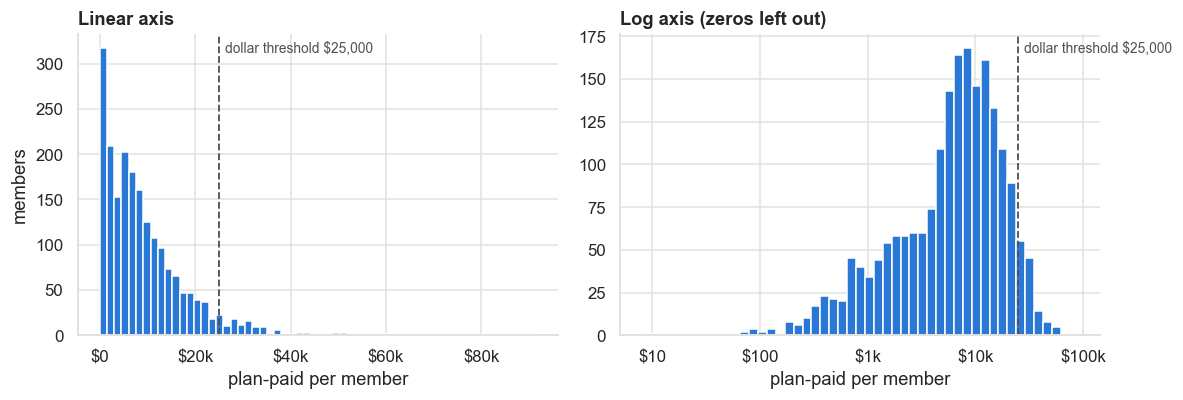

members at $0: 0
mean   $9,295
median $7,057


In [4]:
# ---------------------------------------------------------------------------
# TODO 2 — plot plan-paid per member on a linear axis, then a log axis.
#
# Two histograms side by side, with the dollar threshold on both. Then
# print the mean and the median.
#
# Given: `paid` (dollars per member) and threshold_line(ax), both in the
# helpers cell. A log axis can't show $0, so leave zeros out of that panel,
# and space the bins evenly in log terms rather than in dollars.
#
# Docs that will help:
#   - pyplot.subplots
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html
#   - Axes.hist
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.hist.html
#   - Axes.set_xscale
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set_xscale.html
#   - numpy.logspace
#     https://numpy.org/doc/stable/reference/generated/numpy.logspace.html
#   - Series.mean / Series.median
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.median.html
# ---------------------------------------------------------------------------

# your code here
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(paid, bins=60, color=BLUE)
axes[0].set(title="Linear axis", xlabel="plan-paid per member", ylabel="members")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(usd))
threshold_line(axes[0])

positive = paid[paid > 0]
bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 50)
axes[1].hist(positive, bins=bins, color=BLUE)
axes[1].set_xscale("log")
axes[1].set(title="Log axis (zeros left out)", xlabel="plan-paid per member")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(usd))
threshold_line(axes[1])

plt.tight_layout()
plt.show()

print(f"members at $0: {(paid == 0).sum()}")
print(f"mean   ${paid.mean():,.0f}")
print(f"median ${paid.median():,.0f}")

**What you should see.** On the linear axis, most members are squeezed to the
left and a long tail stretches to the right. On the log axis the shape is easy
to read. The mean is higher than the median (median around $6k–9k).

**Your conclusion**: which number better describes a typical member, the mean or the median? Why?

> The median ($7,057) describes a typical member better than the mean ($9,295). The distribution has a long right tail, and a few very expensive members pull the mean up by about $2,200. Half of members cost less than the median, while the mean is a number that fewer members sit near.

### How much spend sits with the top few?

Last week: in real US healthcare, the costliest 5% of people drive about half
of all spending. Check whether your cohort looks like that.

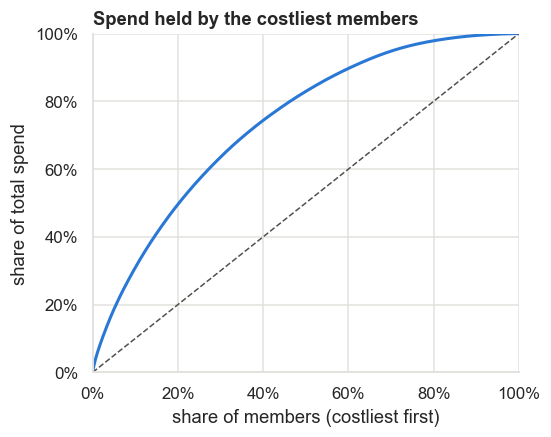

top   5% of members hold 18.6% of spend
top  10% of members hold 30.9% of spend
top  20% of members hold 49.6% of spend


In [5]:
# ---------------------------------------------------------------------------
# TODO 3 — share of total spend held by the top X% of members.
#
# Sort members from most to least expensive. Plot the running share of
# total spend (y) against the share of members counted so far (x). Add a
# dashed diagonal for "everyone costs the same". Then print the share
# held by the top 5%, 10% and 20%.
#
# Docs that will help:
#   - numpy.sort  (it sorts ascending; how do you reverse it?)
#     https://numpy.org/doc/stable/reference/generated/numpy.sort.html
#   - numpy.cumsum
#     https://numpy.org/doc/stable/reference/generated/numpy.cumsum.html
#   - numpy.arange
#     https://numpy.org/doc/stable/reference/generated/numpy.arange.html
#   - Axes.plot  (see the linestyle argument)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html
# ---------------------------------------------------------------------------

# your code here
sorted_paid = np.sort(paid.to_numpy())[::-1]
spend_share = np.cumsum(sorted_paid) / sorted_paid.sum()
member_share = np.arange(1, len(sorted_paid) + 1) / len(sorted_paid)

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(member_share, spend_share, color=BLUE, linewidth=2)
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
ax.set(title="Spend held by the costliest members",
       xlabel="share of members (costliest first)", ylabel="share of total spend",
       xlim=(0, 1), ylim=(0, 1))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

for top in (0.05, 0.10, 0.20):
    k = int(round(top * len(sorted_paid)))
    print(f"top {top:>4.0%} of members hold {spend_share[k - 1]:.1%} of spend")

**What you should see.** A curve that bows above the diagonal. The top 20% of
members hold roughly 45–52% of spend.

**Your conclusion**: your top 5% hold 18.6% of spend. Is that more or less than the ~50% in real life?

> In my cohort the top 5% hold 18.6% of spend, and the top 20% hold 49.6%. That is less concentrated than the ~50% in real life, which comes from the top 5%. My cohort is synthetic and its costs are spread more evenly. It does bow above the diagonal, so spend is still skewed, just not as extremely as in real data.

---

## 4. The label is a line someone drew

`is_high_cost` is 1 when a member's plan-paid is over the **dollar threshold**
(`HIGH_COST_THRESHOLD_USD` in `config.py`, $25,000). It is a choice, not a fact
about the member.

In [6]:
# ---------------------------------------------------------------------------
# TODO 4 — your prevalence.
#
# Print how many members are high-cost, and what share of all members that
# is. Then print the accuracy of a "model" that predicts nobody is
# high-cost. (Who would that model get right?)
#
# Docs that will help:
#   - Series.sum
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.sum.html
#   - Series.mean  (the mean of a 0/1 column is a share)
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.mean.html
# ---------------------------------------------------------------------------

# your code here
n_high = int(summary["is_high_cost"].sum())
prevalence = summary["is_high_cost"].mean()
print(f"high-cost members: {n_high} of {len(summary):,}  ({prevalence:.1%})")
print(f"accuracy of predicting nobody is high-cost: {1 - prevalence:.1%}")

high-cost members: 115 of 2,000  (5.8%)
accuracy of predicting nobody is high-cost: 94.2%


**What you should see.** A prevalence between 4% and 9%, so predicting nobody
scores 91%–96% accuracy.

**Your conclusion**: a classmate says their model is 94% accurate. Why isn't that impressive here?

> Predicting that nobody is high-cost already scores 94.2%, because only 5.8% of members (115 of 2,000) are high-cost. A model has to beat that baseline to add anything, and accuracy hides the thing we care about: it can miss every high-cost member and still look excellent. Precision, recall or similar metrics on the rare class are needed.

### What if the line were somewhere else?

$25,000 is a choice. In TODO 4 you asked "what share of members cost more than
$25k?" Now ask the same question for other dollar amounts, from $2,500 up to
$60,000, and plot the answers.

Think of the bar for calling someone "tall": set it at 5 feet and nearly
everyone is tall; set it at 7 feet and almost nobody is.

over $ 2,500:  76.8% of members
over $ 5,000:  63.7% of members
over $10,000:  35.0% of members
over $15,000:  19.6% of members
over $20,000:  10.8% of members
over $25,000:   5.8% of members
over $30,000:   3.2% of members
over $40,000:   0.9% of members
over $50,000:   0.4% of members
over $60,000:   0.1% of members


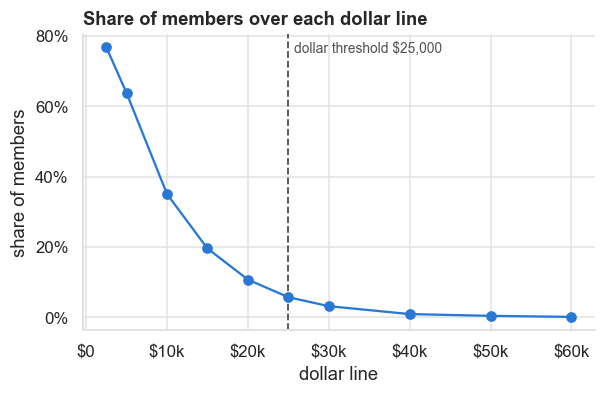


members over $50,000: 9


In [7]:
# ---------------------------------------------------------------------------
# TODO 5 — move the line.
#
# Worked example: the share of members who cost more than $5,000.
#
#     paid > 5_000              -> True/False for every member
#     (paid > 5_000).mean()     -> the share that are True (True counts as 1)
#     (paid > 5_000).sum()      -> the NUMBER that are True
#
# Your steps:
#   1. Make a list to hold your answers:   shares = []
#   2. Loop over `lines` (given below). For each one, work out the share of
#      members above it, the same way as the example, and append it.
#   3. Print each line next to its share, so you can read off $10,000.
#   4. Plot `lines` (x) against `shares` (y) with ax.plot, add dots with
#      marker="o", and call threshold_line(ax) to mark $25k.
#   5. Print the NUMBER of members above $50,000.
#
# Docs that will help:
#   - Comparing a Series to a number gives True/False
#     https://pandas.pydata.org/docs/user_guide/indexing.html#boolean-indexing
#   - Python for loops and list.append
#     https://docs.python.org/3/tutorial/controlflow.html#for-statements
#   - Axes.plot  (see the marker argument)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.plot.html
# ---------------------------------------------------------------------------

lines = [2_500, 5_000, 10_000, 15_000, 20_000, 25_000, 30_000, 40_000, 50_000, 60_000]

# your code here
shares = []
for line in lines:
    shares.append((paid > line).mean())

for line, share in zip(lines, shares):
    print(f"over ${line:>6,}: {share:6.1%} of members")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(lines, shares, marker="o", color=BLUE)
threshold_line(ax)
ax.set(title="Share of members over each dollar line",
       xlabel="dollar line", ylabel="share of members")
ax.xaxis.set_major_formatter(plt.FuncFormatter(usd))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.show()

print()
print(f"members over $50,000: {int((paid > 50_000).sum())}")

**What you should see.** A curve that starts high and drops fast. At $10k,
30–45% of members are over the line; above $50k, only a handful of *members*
(a count, not a percentage).

**Your conclusion**: what goes wrong if the line is set much lower, or much higher?

> If the line is set much lower (say $2,500), 77% of members are above it, so the label is no longer rare and it stops picking out the costly few. If it is set much higher ($50k and up), only 9 members are over it, which is too few positives to train on or to measure a model with. The $25k line leaves 5.8% positives, rare but still enough to learn from. Because the line is a choice, the prevalence changes with it.

---

## 5. Do some groups have more high-cost members?

**The question.** Are older members more likely to be high-cost than younger
ones? Women more than men? One region more than another?

**Step 1: the rate.** For each group, divide the high-cost members by all the
members in that group. 20 high-cost out of 400 members is a rate of 5%.

**Step 2: why a rate on its own can fool you.** High-cost members are rare, so
each group only has a few dozen of them. With numbers that small, luck moves
the rate a lot. Two groups can look different when the gap is just chance.

Think of coin flips: 7 heads in 10 flips doesn't prove a coin is unfair, but
700 heads in 1,000 flips does. The more flips, the more you can trust the
result.

**Step 3: the 95% interval.** This is the range the group's *true* rate
probably sits in, given how many members we have. Fewer members means a wider
range. Both of these are 5%, but we're much surer about the second:

| High-cost / members | Rate | 95% interval |
|---|---|---|
| 5 / 100 | 5% | 2.2% to 11.2% |
| 50 / 1,000 | 5% | 3.8% to 6.5% |

**How to read the plot.** Each group gets one row:

```
            0%        5%        10%
Group A        |----●----|                ● = the group's rate
Group B             |------●------|       |--| = its 95% interval
                     ¦                    ¦ (dashed) = rate for everyone
```

- **The lines overlap:** you can't say the groups differ. The gap could be luck.
- **The lines don't overlap:** the difference is probably real.

Example: Group A is 20 / 400 = 5% (3.3% to 7.6%). Group B is 30 / 400 = 7.5%
(5.3% to 10.5%). B looks higher, but the ranges overlap, so you **can't** claim
a difference.

**What you'll write.** For each variable, one of two sentences:

- "*X* has a higher rate than *Y*, and their intervals don't overlap."
- "No detectable difference at this sample size."

The second one is a complete answer. It does **not** mean "there is no
difference"; it means we don't have enough members to tell.

**Why it matters.** If the data has a real gap between groups, a model trained
on it will learn that gap too. Week 6 asks whether that's fair.

              n  positives   rate     lo     hi
age_bucket                                     
18-29       286          6  0.021  0.010  0.045
30-39       434         20  0.046  0.030  0.070
40-49       579         26  0.045  0.031  0.065
50-59       506         35  0.069  0.050  0.095
60-64       195         28  0.144  0.101  0.200 



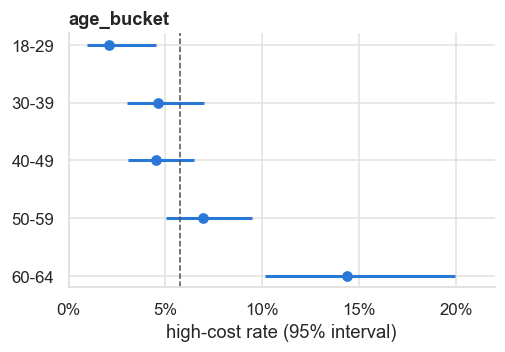

        n  positives   rate    lo     hi
sex                                     
F     972         62  0.064  0.05  0.081
M    1028         53  0.052  0.04  0.067 



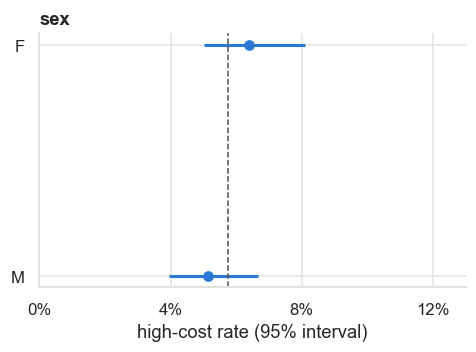

             n  positives   rate     lo     hi
region                                        
Midwest    403         23  0.057  0.038  0.084
Northeast  400         22  0.055  0.037  0.082
Southeast  425         29  0.068  0.048  0.096
Southwest  380         20  0.053  0.034  0.080
West       392         21  0.054  0.035  0.081 



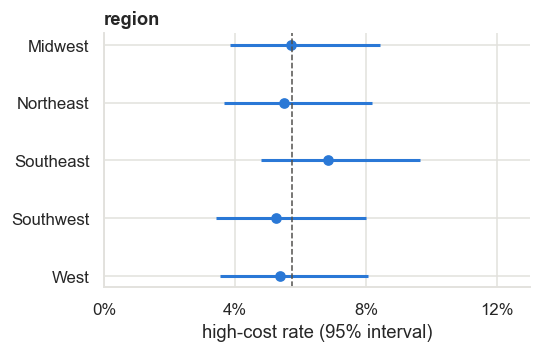

In [8]:
# ---------------------------------------------------------------------------
# TODO 6 — high-cost rate by group, with 95% intervals.
#
# Worked example: count members and high-cost members in each age bucket.
#
#     table = summary.groupby("age_bucket")["is_high_cost"].agg(n="size", positives="sum")
#
#   n         = members in the group
#   positives = high-cost members (is_high_cost is 0/1, so the sum counts the 1s)
#
# Your steps, starting with age_bucket:
#   1. Run the worked example. Then put the buckets in order:
#          table = table.reindex(AGE_ORDER)
#   2. Add a "rate" column: positives divided by n.
#   3. Add "lo" and "hi" columns with the given helper:
#          table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
#   4. print(table), then plot it with the given helper:
#          fig, ax = plt.subplots(figsize=(5, 3))
#          plot_rates(table, ax, "age_bucket")
#   5. Do the same for "sex" and "region". Skip the reindex step; those
#      groups have no natural order.
#
# Docs that will help:
#   - DataFrame.groupby
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html
#   - Adding a new column from existing ones
#     https://pandas.pydata.org/docs/getting_started/intro_tutorials/05_add_columns.html
#   - Series.reindex
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html
# ---------------------------------------------------------------------------

# your code here
for col in DEMOGRAPHIC_COLUMNS:
    table = summary.groupby(col)["is_high_cost"].agg(n="size", positives="sum")
    if col == "age_bucket":
        table = table.reindex(AGE_ORDER)
    table["rate"] = table["positives"] / table["n"]
    table["lo"], table["hi"] = wilson_interval(table["positives"], table["n"])
    print(table.round(3), "\n")

    fig, ax = plt.subplots(figsize=(5, 3))
    plot_rates(table, ax, col)
    if table["hi"].max() > 0.13:  # the helper's x axis stops at 13%; widen it so nothing is cut off
        ax.set_xlim(0, 0.22)
        ax.set_xticks([0, 0.05, 0.10, 0.15, 0.20])
    plt.show()

**What you should see.** `sex` and `region` rates within a few points of each
other, with intervals that overlap. `age_bucket` usually rises with age, but in
some cohorts even age is too close to call.

**Your conclusion**: which variable, if any, shows a difference you can defend? For the others, write "no detectable difference at this sample size".

> `age_bucket` shows a difference I can defend: the rate rises from 2.1% (18-29) to 14.4% (60-64), and the 18-29 and 60-64 intervals (1.0%-4.5% vs 10.1%-20.0%) do not overlap. For `sex` (F 6.4% vs M 5.2%) and `region` (5.3%-6.8%), the intervals overlap heavily: no detectable difference at this sample size.

---

## 6. One question for every column

The prediction is made on **January 1**. The label is only known after
**December 31**. So, for each column in `member_summary.csv`:

> **"On the day I need this prediction, do I already know this number?"**

**TODO 7: fill in the last column.** No code. Write *Yes*, *No* or
*Debatable*, and a few words of why. Look at how each column is defined, not at
how well it correlates with the label.

- **Yes:** you'd know it on January 1.
- **No:** it's the outcome, or nearly the same number as the outcome.
- **Debatable:** you'd know a version of it on January 1, but this column was
  measured over the same year as the label.

| Column | What it is | Known on day one? |
|---|---|---|
| `age_bucket` | banded age | Yes — fixed at the start of the year |
| `sex` | recorded sex | Yes — recorded in enrollment |
| `region` | US region | Yes — enrollment information |
| `total_claims` | approved claims in the year | Debatable — this year's count is not known on Jan 1; last year's would be |
| `medical_claims` | of those, non-pharmacy | Debatable — same year as the label; use last year's |
| `pharmacy_claims` | of those, pharmacy | Debatable — same year as the label; use last year's |
| `specialty_drug_fills` | specialty fills in the year | Debatable — same year as the label; last year's fills are known |
| `total_billed_cents` | what providers billed | No — built from the same year's claims that make up the label |
| `total_allowed_cents` | what the plan allowed | No — nearly the same number as the outcome |
| `total_plan_paid_cents` | what the plan paid | No — this is the outcome the label is cut from |
| `total_oop_cents` | what the member paid | No — a part of the same year's spend, only known after the claims |
| `unique_diagnosis_codes` | distinct diagnoses seen | Debatable — this year's diagnoses show up as claims come in; last year's are known |
| `inpatient_claims` | institutional claims | Debatable — same year as the label; last year's are known |
| `has_specialty_drug` | any specialty fill | Debatable — same year as the label; last year's are known |
| `is_high_cost` | the label | No — it is the label, known only after Dec 31 |

Hint: this data covers one plan year. A real system would use *last* year's
claims to predict *this* year. Which columns could you get from last year?

**Your conclusion**: which row was hardest to decide, and why?

> `total_claims` (and the other claim counts) were the hardest. They are not the outcome, but they are measured over the same year as the label. On Jan 1 you would not have them for this year, yet last year's version would be known and probably useful, so the answer depends on whether you use this year's or last year's data. The money columns were easy by comparison, because they are the label or nearly the same number as the label.

`tests/test_leakage.py` fails until Weeks 3–4. That is on purpose, and this
table is what it is about.

---

## 7. Four checks before you trust a figure

In [9]:
# ---------------------------------------------------------------------------
# TODO 8a — missing or structural?
#
# Print the share of blanks in each column of claims that has any. Then
# compare those shares with the share of claims that are pharmacy.
#
# Docs that will help:
#   - DataFrame.isna
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.isna.html
#   - DataFrame.mean
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html
# ---------------------------------------------------------------------------

# your code here
blank_share = claims.isna().mean()
blank_share = blank_share[blank_share > 0]
print("share of claims that are blank, by column:")
print(blank_share.map("{:.1%}".format).to_string())
print()
print(f"share of claims that are pharmacy:     {claims['is_pharmacy'].mean():.1%}")
print(f"share of claims that are NOT pharmacy: {1 - claims['is_pharmacy'].mean():.1%}")
print()
print("blank diagnosis_code, by claim_type:")
print(claims.groupby("claim_type")["diagnosis_code"].apply(lambda s: s.isna().mean()).map("{:.1%}".format).to_string())

share of claims that are blank, by column:
diagnosis_code       21.8%
procedure_code       21.8%
drug_name            78.2%
therapeutic_class    78.2%

share of claims that are pharmacy:     21.8%
share of claims that are NOT pharmacy: 78.2%

blank diagnosis_code, by claim_type:
claim_type
Institutional      0.0%
Pharmacy         100.0%
Professional       0.0%


**What you should see.** No blanks in `members` or `summary`. In `claims`, some
columns blank on about 23% of rows and others on about 77%.

**Your conclusion**: is a blank `diagnosis_code` on a pharmacy claim missing data? What would go wrong if you filled it in?

> No, it is structural, not missing data. 21.8% of claims are pharmacy, and exactly those are blank in `diagnosis_code` and `procedure_code`, because a pharmacy fill has no diagnosis or procedure. The other 78.2% (medical claims) are blank in `drug_name` and `therapeutic_class`. If I filled the blanks in, for example with the most common code, I would invent diagnoses that never happened and a model could learn from them.

In [10]:
# ---------------------------------------------------------------------------
# TODO 8b — does the money add up?
#
# Every claim should satisfy  plan_paid + out_of_pocket == allowed.
# Print the share of claims where it holds, for each claim_type.
#
# Docs that will help:
#   - Arithmetic and comparisons on columns
#     https://pandas.pydata.org/docs/user_guide/basics.html#flexible-binary-operations
#   - Series.groupby
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.groupby.html
# ---------------------------------------------------------------------------

# your code here
adds_up = (claims["plan_paid_cents"] + claims["out_of_pocket_cents"]) == claims["allowed_cents"]
print("share of claims where plan_paid + out_of_pocket == allowed:")
print(adds_up.groupby(claims["claim_type"]).mean().map("{:.1%}".format).to_string())

share of claims where plan_paid + out_of_pocket == allowed:
claim_type
Institutional    91.4%
Pharmacy          0.0%
Professional     92.3%


**What you should see.** The identity holds for most medical claims and for
**none** of the pharmacy claims.

**Your conclusion**: the identity fails on some claims. Why does that matter before you build features from these columns?

> The identity holds for 91.4% of institutional and 92.3% of professional claims, and for 0% of pharmacy claims. The pharmacy rows have a plan_paid plus out_of_pocket that does not equal the allowed amount, and about 8% of medical claims also fail. In those medical claims the plan paid $0 and the member's out-of-pocket amount is larger than the allowed amount (the copay plus deductible and coinsurance exceeds the allowed amount on cheap claims, so plan-paid is clamped to zero). Pharmacy claims fail for a different reason: their out-of-pocket amount is a fixed $5-30 that is not tied to the allowed amount. If I build features that add or compare these columns, such as total cost or the member's share, they would be wrong for pharmacy and I would need to understand why before using them.

In [11]:
# ---------------------------------------------------------------------------
# TODO 8c — do the counts match?
#
# For each member, does summary's total_claims equal (i) ALL their claims,
# or (ii) only their APPROVED claims? Print the share of members that match
# each. Members with no claims at all should count as 0, not be dropped.
#
# Docs that will help:
#   - DataFrameGroupBy.size
#     https://pandas.pydata.org/docs/reference/api/pandas.api.typing.DataFrameGroupBy.size.html
#   - DataFrame.set_index
#     https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.set_index.html
#   - Series.reindex  (see fill_value)
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.reindex.html
# ---------------------------------------------------------------------------

# your code here
all_claims = claims.groupby("member_id").size()
approved_claims = claims[claims["adjudication_status"] == "approved"].groupby("member_id").size()

check = summary.set_index("member_id")["total_claims"].to_frame()
check["all"] = all_claims.reindex(check.index, fill_value=0)
check["approved"] = approved_claims.reindex(check.index, fill_value=0)

print(f"total_claims == ALL claims:      {(check['total_claims'] == check['all']).mean():.1%} of members")
print(f"total_claims == APPROVED claims: {(check['total_claims'] == check['approved']).mean():.1%} of members")
print()
print(claims["adjudication_status"].value_counts().to_string())

total_claims == ALL claims:      50.4% of members
total_claims == APPROVED claims: 100.0% of members

adjudication_status
approved    20249
denied       1416


**What you should see.** One of the two matches for 100% of members.

**Your conclusion**: which claims does `member_summary.csv` count, and why?

> `member_summary.csv` counts only approved claims: `total_claims` matches the approved count for 100% of members, but the count of all claims for only 50.4%. 1,416 claims are denied, and a denied claim costs the plan nothing, so the summary leaves them out. Any feature I rebuild from `claims.csv` has to filter on `adjudication_status == 'approved'` to match.

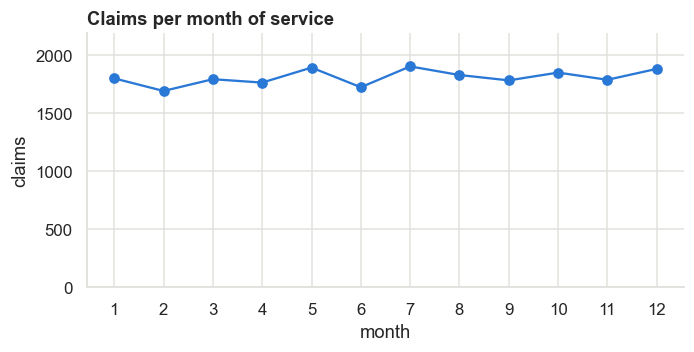

service_date
1     1797
2     1689
3     1790
4     1761
5     1890
6     1721
7     1900
8     1826
9     1780
10    1847
11    1785
12    1879


In [12]:
# ---------------------------------------------------------------------------
# TODO 8d — any time pattern?
#
# Plot the number of claims in each month of service_date, as a line.
# Start the y axis at 0 so small wiggles don't look big.
#
# Docs that will help:
#   - pandas.to_datetime
#     https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
#   - Series.dt.month
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.dt.month.html
#   - Series.value_counts and Series.sort_index
#     https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html
#   - Axes.set  (ylim=...)
#     https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.set.html
# ---------------------------------------------------------------------------

# your code here
month = pd.to_datetime(claims["service_date"]).dt.month
per_month = month.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(per_month.index, per_month.values, marker="o", color=BLUE)
ax.set(title="Claims per month of service", xlabel="month", ylabel="claims",
       ylim=(0, per_month.max() * 1.15), xticks=range(1, 13))
plt.show()
print(per_month.to_string())

**What you should see.** A roughly flat line.

**Your conclusion**: is there a seasonal pattern? What does that mean for features like "month of first claim"?

> No. The line stays between about 1,700 and 1,900 claims per month, with no clear seasonal pattern, so this is just random variation. It means a feature like month of first claim would carry little information about the member, and I should not expect a seasonal effect (such as a winter peak) in this data.

---

## 8. What to carry into Week 3

Fill in your numbers. These are the start of your Week 8 slides.

**The prediction target**

| | |
|---|---|
| Label column | `is_high_cost` |
| It is 1 when | `total_plan_paid_cents` (plan-paid over the year) is over $25,000 |
| Measured over | one plan year (the 2024 plan year) |
| Predicted on | January 1, before any of that year's claims happen |
| Kind of problem | Classification (high-cost: yes/no) |

**Your cohort**

| Finding | Your number |
|---|---|
| Claims rows per member | about 10.8 (21,665 claims for 2,000 members) |
| Median vs. mean plan-paid | $7,057 vs. $9,295 |
| Share of spend held by the top 5% | 18.6 % |
| Prevalence at $25k | 5.8 % (115 members) |
| Accuracy of predicting nobody | 94.2 % |
| Columns marked Yes / Debatable / No | 3 / 7 / 5 |

## Before you open your PR

- [ ] `pytest tests/test_data.py -v` — nine passing
- [ ] Every `______` is filled in
- [ ] **Kernel → Restart & Run All** works top to bottom
- [ ] The seed printed in section 0 is the one you were assigned
- [ ] Nothing in `data/` is staged — `git status` should not list it

Then commit the notebook, open a PR, and review your partner's. Their seed is
different, so ask how they got their numbers rather than comparing values.